# 07 Cross-dataset test: MATR to HUST

HUST (Ma et al., 2022) uses the same A123 LFP/graphite 1.1 Ah cell, but the opposite design: every cell is charged the same way and discharged with a different multi-stage protocol. MATR varied the charging and kept discharge fixed. So the question is whether a model that learned how charging damages cells transfers to cells worn out by different discharges.

HUST is read straight from `hust_data.zip` with `src/hust.py`. To compare like with like, MATR's Q(V) curves are rebuilt from raw samples the same way (`use_precomputed=False`) instead of using the precomputed ones.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import FIGURES_DIR, ROOT, PROCESSED_DIR
from src.data import load_cache, build_cache
from src.hust import HUST_CACHE, build_hust_cache, hust_feature_table
from src.splits import TRAIN, PRIMARY_TEST, SECONDARY_TEST
from src.features import build_feature_table, DISCHARGE_FEATURES, VARIANCE_FEATURES
from src.models import make_elastic_net, conformal_intervals, coverage
from src.evaluate import score, parity_plot

raw_path = ROOT / "data/cache/matr_rawcurves.pkl"
matr_raw = load_cache(raw_path) if raw_path.exists() else build_cache(PROCESSED_DIR, raw_path, use_precomputed=False)
hust = load_cache(HUST_CACHE) if HUST_CACHE.exists() else build_hust_cache()
print(len(matr_raw), "MATR cells,", len(hust), "HUST cells")

180 MATR cells, 77 HUST cells


## Check: rebuilt MATR curves vs the precomputed ones

If rebuilding the curves changed the results a lot, any HUST gap could just be a processing difference.

In [2]:
matr_pre = load_cache()
rows = []
for label, cc in [("precomputed", matr_pre), ("rebuilt from raw", matr_raw)]:
    tr = build_feature_table(cc, TRAIN)
    m = make_elastic_net().fit(tr[DISCHARGE_FEATURES], tr["cycle_life"])
    for s, ids in [("primary_test", PRIMARY_TEST), ("secondary_test", SECONDARY_TEST)]:
        t = build_feature_table(cc, ids)
        rows.append({"curves": label, "split": s, **score(t["cycle_life"], m.predict(t[DISCHARGE_FEATURES]))})
pd.DataFrame(rows).pivot(index="curves", columns="split").round(1)

RMSE (cycles)                    MAPE (%)               
split             primary_test secondary_test primary_test secondary_test
curves                                                                   
precomputed              221.2          143.9         13.6           10.4
rebuilt from raw         148.6          178.8         10.8            9.6

Same ballpark, so the pipeline is fine. The primary set even gets better because the rebuilt curves don't have b1c41's glitch (notebook 06).

## HUST labels

HUST tests stop when our integrated capacity is about 0.90 Ah, just above the 0.88 Ah threshold, so `cycle_life()` finds no end of life for any cell. The dataset ships its own label (`rul` at cycle 1 equals the number of recorded cycles), which is what `hust_feature_table` uses. HUST lifetimes are therefore slightly conservative compared with the MATR definition.

In [3]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # HUST has no temperature / IR logs

train = build_feature_table(matr_raw, TRAIN)
hust_all = hust_feature_table(hust)
print("HUST cells with NaN discharge features:", int(hust_all[DISCHARGE_FEATURES].isna().any(axis=1).sum()))
pd.DataFrame({"MATR train": train["cycle_life"].describe(), "HUST": hust_all["cycle_life"].describe()}).round(0)

HUST cells with NaN discharge features: 0


,MATR train,HUST
count,41.0,77.0
mean,672.0,1898.0
std,327.0,390.0
min,299.0,1142.0
25%,476.0,1609.0
50%,526.0,1873.0
75%,786.0,2202.0
max,2158.0,2689.0


## Zero-shot: train on MATR only

In [4]:
matr_test = build_feature_table(matr_raw, PRIMARY_TEST)
rows = []
for name, feats in [("elastic net (variance)", VARIANCE_FEATURES), ("elastic net (discharge)", DISCHARGE_FEATURES)]:
    model = make_elastic_net().fit(train[feats], train["cycle_life"])
    rows.append({"model": name, "test set": "MATR primary", **score(matr_test["cycle_life"], model.predict(matr_test[feats]))})
    rows.append({"model": name, "test set": "HUST", **score(hust_all["cycle_life"], model.predict(hust_all[feats]))})
pd.DataFrame(rows).set_index(["model", "test set"]).round(1)

RMSE (cycles)  MAPE (%)
model                   test set                             
elastic net (variance)  MATR primary          135.6      15.4
                        HUST                 1696.5      85.9
elastic net (discharge) MATR primary          148.6      10.8
                        HUST                 1664.8      84.4

90% interval coverage on HUST: 0%
median signed error: -86%


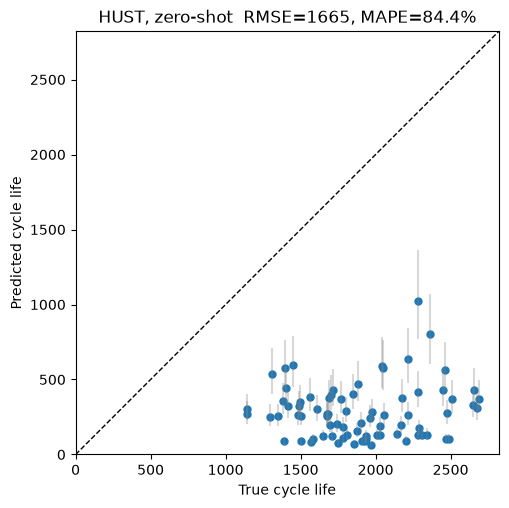

In [5]:
pred, lo, hi = conformal_intervals(make_elastic_net, train[DISCHARGE_FEATURES], train["cycle_life"],
                                   hust_all[DISCHARGE_FEATURES], alpha=0.1)
print(f"90% interval coverage on HUST: {coverage(hust_all['cycle_life'], lo, hi):.0f}%")
print(f"median signed error: {np.median(100 * (pred - hust_all['cycle_life']) / hust_all['cycle_life']):+.0f}%")
fig, ax = plt.subplots(figsize=(5.5, 5.5))
parity_plot(hust_all["cycle_life"], pred, title="HUST, zero-shot", ax=ax, lower=lo, upper=hi)
fig.savefig(FIGURES_DIR / "hust_zero_shot.png", dpi=150, bbox_inches="tight")

The model under-predicts nearly every HUST cell and the intervals cover none of them. The intervals assume test cells look like training cells, which clearly isn't the case here.

## Why: distribution shift

,% of HUST cells outside MATR train range
dq_log_min,100.0
dq_log_var,74.0
dq_log_skew,86.0
dq_log_kurt,100.0
qd_cycle2,100.0
qd_max_minus_cycle2,100.0
cycle_life,29.0


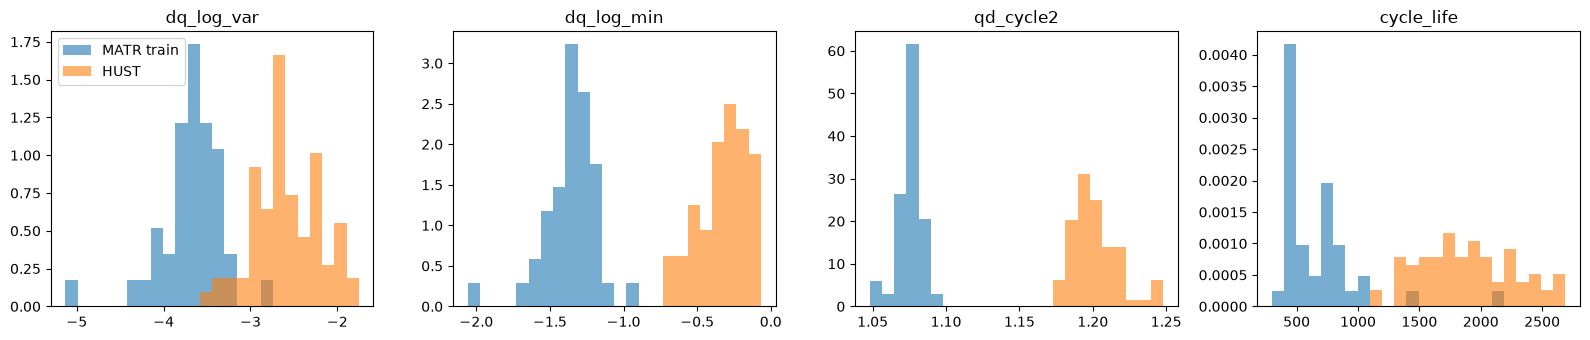

In [6]:
show = ["dq_log_var", "dq_log_min", "qd_cycle2", "cycle_life"]
fig, axes = plt.subplots(1, len(show), figsize=(16, 3.5))
for ax, col in zip(axes, show):
    bins = np.linspace(min(train[col].min(), hust_all[col].min()), max(train[col].max(), hust_all[col].max()), 25)
    ax.hist(train[col], bins=bins, alpha=0.6, density=True, label="MATR train")
    ax.hist(hust_all[col], bins=bins, alpha=0.6, density=True, label="HUST")
    ax.set_title(col)
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "transfer_shift.png", dpi=150, bbox_inches="tight")

outside = {c: ((hust_all[c] < train[c].min()) | (hust_all[c] > train[c].max())).mean() * 100
           for c in DISCHARGE_FEATURES + ["cycle_life"]}
pd.Series(outside).round(0).to_frame("% of HUST cells outside MATR train range")

Almost every HUST cell is outside the MATR training range on most features. HUST's high-rate multi-stage discharges change the shape of the Q(V) curve by themselves, so its ΔQ looks like that of a short-lived MATR cell, even though HUST cells live 2 to 3 times longer. In MATR the discharge was identical for every cell, so ΔQ only reflected damage; in HUST it also reflects the protocol. (The higher `qd_cycle2` is partly because HUST capacity is integrated from current here, not taken from the cycler.)

## Few-shot: how many HUST cells does it take?

Add k random HUST cells to the MATR training set and score on the remaining HUST cells. Repeated 10 times per k, because which cells you pick matters.

                 MAPE (%)      RMSE (cycles)       
                     mean  std          mean    std
HUST cells added                                   
0                    84.4  0.0        1664.8    0.0
5                    28.3  4.6         695.8  109.6
10                   25.2  2.9         648.7  111.0
20                   22.6  3.7         557.4  102.7


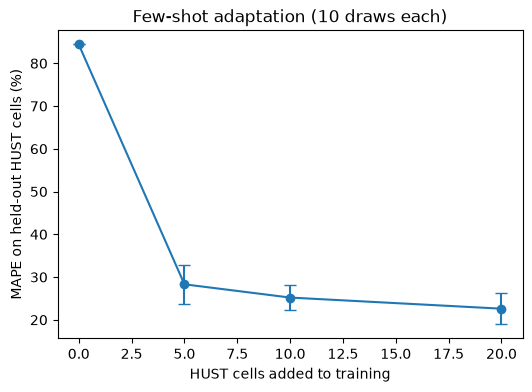

In [7]:
rng = np.random.default_rng(0)
hust_ids = list(hust_all.index)
rows = []
for k in [0, 5, 10, 20]:
    for rep in range(10):
        added = list(rng.choice(hust_ids, size=k, replace=False)) if k else []
        held_out = [c for c in hust_ids if c not in added]
        fit_df = pd.concat([train, hust_all.loc[added]])
        m = make_elastic_net().fit(fit_df[DISCHARGE_FEATURES], fit_df["cycle_life"])
        rows.append({"HUST cells added": k,
                     **score(hust_all.loc[held_out, "cycle_life"], m.predict(hust_all.loc[held_out, DISCHARGE_FEATURES]))})
few = pd.DataFrame(rows).groupby("HUST cells added")[["MAPE (%)", "RMSE (cycles)"]].agg(["mean", "std"]).round(1)
print(few)

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(few.index, few[("MAPE (%)", "mean")], yerr=few[("MAPE (%)", "std")], marker="o", capsize=4)
ax.set(xlabel="HUST cells added to training", ylabel="MAPE on held-out HUST cells (%)", title="Few-shot adaptation (10 draws each)")
fig.savefig(FIGURES_DIR / "few_shot.png", dpi=150, bbox_inches="tight")

## Summary

- Zero-shot, the MATR model is off by about 84% on HUST and none of the 90% intervals cover the truth.
- The cause is a clear distribution shift: the ΔQ features mix up "damage" and "discharge protocol" once the protocol varies.
- Adding just 5 to 10 HUST cells brings the error down to roughly 25 to 28%. The remaining gap to in-domain (about 11 to 14%) suggests features that don't depend on the discharge protocol would be the next thing to try.